# Etapa 6 — Bloom Filter con REES46

In [1]:

from pathlib import Path
import sys

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.bloom_filter import BloomFilter

# Crear Bloom Filter para 100,000 eventos
bloom = BloomFilter(
    expected_items=100000,
    false_positive_rate=0.01
)

# Insertar IDs de ejemplo
inserted_ids = [100, 200, 300, 400, 500]

for event_id in inserted_ids:
    bloom.add(event_id)

print("=== CONFIGURACIÓN BLOOM FILTER ===")
print("Bits:", bloom.num_bits)
print("Funciones hash:", bloom.num_hashes)
print("Memoria (KiB):", round(bloom.memory_bytes() / 1024, 2))
print("Inserciones:", bloom.items_added)

print("\n=== CONSULTAS ===")

for event_id in [100, 200, 300, 999]:
    print(
        f"Evento {event_id}:",
        "Posiblemente existe" if bloom.contains(event_id)
        else "Definitivamente no existe"
    )

# No debe haber falsos negativos
assert all(bloom.contains(x) for x in inserted_ids)

print("\n¡Bloom Filter validado en la prueba inicial!")


=== CONFIGURACIÓN BLOOM FILTER ===
Bits: 958506
Funciones hash: 7
Memoria (KiB): 117.01
Inserciones: 5

=== CONSULTAS ===
Evento 100: Posiblemente existe
Evento 200: Posiblemente existe
Evento 300: Posiblemente existe
Evento 999: Definitivamente no existe

¡Bloom Filter validado en la prueba inicial!


## 2. Evaluación experimental de falsos positivos

In [2]:

import time
import numpy as np
import pandas as pd

from src.bloom_filter import BloomFilter

N = 100_000
TARGET_FPR = 0.01

# Crear un filtro nuevo para el experimento
bloom_exp = BloomFilter(
    expected_items=N,
    false_positive_rate=TARGET_FPR
)

# IDs únicos de la muestra inicial REES46
inserted_ids = range(0, N)

# IDs nuevos, disjuntos de los insertados
new_ids = range(N, 2 * N)

# 1. Insertar eventos
start = time.perf_counter()

for event_id in inserted_ids:
    bloom_exp.add(event_id)

insertion_time = time.perf_counter() - start

# 2. Verificar falsos negativos
false_negatives = sum(
    not bloom_exp.contains(event_id)
    for event_id in inserted_ids
)

# 3. Medir falsos positivos
start = time.perf_counter()

false_positives = sum(
    bloom_exp.contains(event_id)
    for event_id in new_ids
)

query_time = time.perf_counter() - start

# 4. Calcular métricas
observed_fpr = false_positives / N
estimated_fpr = bloom_exp.estimated_fpr()

print("=== BLOOM FILTER: EVALUACIÓN EXPERIMENTAL ===")
print(f"Elementos insertados: {N:,}")
print(f"Consultas nuevas: {N:,}")
print(f"Memoria: {bloom_exp.memory_bytes()/1024:.2f} KiB")
print(f"Funciones hash: {bloom_exp.num_hashes}")

print("\n=== EXACTITUD ===")
print("Falsos negativos:", false_negatives)
print("Falsos positivos:", false_positives)
print(f"Tasa objetivo: {TARGET_FPR:.2%}")
print(f"Tasa teórica aproximada: {estimated_fpr:.2%}")
print(f"Tasa observada: {observed_fpr:.2%}")

print("\n=== RENDIMIENTO ===")
print(f"Tiempo de inserción: {insertion_time:.4f} s")
print(f"Tiempo de consultas nuevas: {query_time:.4f} s")

assert false_negatives == 0
assert 0 <= observed_fpr <= 1

print("\n¡Experimento completado correctamente!")


=== BLOOM FILTER: EVALUACIÓN EXPERIMENTAL ===
Elementos insertados: 100,000
Consultas nuevas: 100,000
Memoria: 117.01 KiB
Funciones hash: 7

=== EXACTITUD ===
Falsos negativos: 0
Falsos positivos: 995
Tasa objetivo: 1.00%
Tasa teórica aproximada: 1.00%
Tasa observada: 1.00%

=== RENDIMIENTO ===
Tiempo de inserción: 0.2141 s
Tiempo de consultas nuevas: 0.1434 s

¡Experimento completado correctamente!


## 3. Comparación de memoria: Bloom Filter vs Hash Set

In [3]:

import sys

# Crear el conjunto exacto equivalente
exact_set = set(range(N))

# Memoria aproximada del conjunto completo
set_memory = (
    sys.getsizeof(exact_set)
    + sum(sys.getsizeof(x) for x in exact_set)
)

bloom_memory = bloom_exp.memory_bytes()

print("=== COMPARACIÓN DE MEMORIA ===")
print(f"Elementos: {N:,}")

print(
    f"Bloom Filter: "
    f"{bloom_memory / 1024**2:.4f} MiB"
)

print(
    f"Hash Set: "
    f"{set_memory / 1024**2:.4f} MiB"
)

print(
    f"Relación de memoria: "
    f"{set_memory / bloom_memory:.2f}x"
)

print("\n=== DIFERENCIA FUNCIONAL ===")
print("Bloom Filter: admite falsos positivos")
print("Hash Set: pertenencia exacta")


=== COMPARACIÓN DE MEMORIA ===
Elementos: 100,000
Bloom Filter: 0.1143 MiB
Hash Set: 6.6705 MiB
Relación de memoria: 58.38x

=== DIFERENCIA FUNCIONAL ===
Bloom Filter: admite falsos positivos
Hash Set: pertenencia exacta


## 4. Deduplicación híbrida: Bloom Filter + Hash Set

In [4]:

from src.hybrid_dedup import HybridDeduplicator

# Crear deduplicador
dedup = HybridDeduplicator(
    expected_items=1000,
    false_positive_rate=0.01
)

# Simular eventos originales y retransmitidos
event_ids = [0, 1, 2, 3, 0, 2, 4, 5, 1, 6]

accepted_events = []

for event_id in event_ids:
    event = {"event_id": event_id}

    if dedup.process(event):
        accepted_events.append(event_id)

metrics = dedup.metrics()

print("=== DEDUPLICACIÓN HÍBRIDA ===")

for key, value in metrics.items():
    print(f"{key}: {value}")

print("\n=== EVENTOS ACEPTADOS ===")
print(accepted_events)

# Validaciones
assert metrics["received"] == 10
assert metrics["accepted"] == 7
assert metrics["duplicates"] == 3
assert metrics["unique_ids"] == 7

assert accepted_events == [0, 1, 2, 3, 4, 5, 6]

print("\n¡Deduplicación híbrida validada!")


=== DEDUPLICACIÓN HÍBRIDA ===
received: 10
accepted: 7
duplicates: 3
bloom_positives: 3
bloom_false_positives: 0
exact_checks: 3
bloom_memory_bytes: 1199
unique_ids: 7

=== EVENTOS ACEPTADOS ===
[0, 1, 2, 3, 4, 5, 6]

¡Deduplicación híbrida validada!


In [5]:
import importlib
import src.pipeline

# Recargar el módulo después de modificar pipeline.py
importlib.reload(src.pipeline)

# Importar la nueva función
from src.pipeline import run_priority_pipeline

print("¡Función importada correctamente!")

¡Función importada correctamente!


## 5. Integración de Bloom Filter al pipeline FIFO

In [6]:

import pandas as pd
import numpy as np
import importlib
from pathlib import Path

import src.pipeline

importlib.reload(src.pipeline)

from src.pipeline import run_ingestion_pipeline

# 1. Cargar eventos reales de REES46
DATA_PATH = PROJECT_DIR / "data" / "raw" / "2019-Oct.csv"

df_test = pd.read_csv(
    DATA_PATH,
    nrows=10
)

# 2. Normalizar los eventos
df_test["event_id"] = np.arange(len(df_test))

df_test["event_timestamp"] = pd.to_datetime(
    df_test["event_time"],
    utc=True
)

# 3. Convertir a registros
eventos_originales = df_test.to_dict("records")

# 4. Simular tres retransmisiones exactas
eventos_prueba = eventos_originales + [
    eventos_originales[0].copy(),
    eventos_originales[3].copy(),
    eventos_originales[7].copy()
]

# 5. Procesar mediante Hash Set
resultado_set = run_ingestion_pipeline(
    eventos_prueba,
    batch_size=4,
    dedup_method="set"
)

# 6. Procesar mediante Bloom + Hash Set
resultado_hybrid = run_ingestion_pipeline(
    eventos_prueba,
    batch_size=4,
    dedup_method="hybrid",
    expected_items=100,
    false_positive_rate=0.01
)

print("=== COMPARACIÓN DE DEDUPLICACIÓN ===")

for nombre, resultado in [
    ("Hash Set", resultado_set),
    ("Bloom + Hash Set", resultado_hybrid)
]:
    metrics = resultado["metrics"]

    print(f"\nMétodo: {nombre}")

    for key, value in metrics.items():
        print(f"{key}: {value}")

# 7. Comparar identificadores
ids_set = [
    event["event_id"]
    for event in resultado_set["events"]
]

ids_hybrid = [
    event["event_id"]
    for event in resultado_hybrid["events"]
]

print("\n=== VERIFICACIÓN DE RESULTADOS ===")
print("IDs Hash Set:", ids_set)
print("IDs híbrido:", ids_hybrid)

assert ids_set == ids_hybrid == list(range(10))
assert resultado_set["metrics"]["output"] == 10
assert resultado_hybrid["metrics"]["output"] == 10
assert resultado_set["metrics"]["duplicates"] == 3
assert resultado_hybrid["metrics"]["duplicates"] == 3

print("\n¡Ambos métodos producen resultados idénticos!")


=== COMPARACIÓN DE DEDUPLICACIÓN ===

Método: Hash Set
received: 13
valid: 13
invalid: 0
duplicates: 3
output: 10
dedup_method: set

Método: Bloom + Hash Set
received: 13
valid: 13
invalid: 0
duplicates: 3
output: 10
dedup_method: hybrid
bloom_positives: 3
bloom_false_positives: 0
exact_checks: 3
bloom_memory_bytes: 120

=== VERIFICACIÓN DE RESULTADOS ===
IDs Hash Set: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
IDs híbrido: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

¡Ambos métodos producen resultados idénticos!


## 6. Benchmark Hash Set vs Bloom Filter + Hash Set

In [7]:

import time
import numpy as np
import pandas as pd

from src.hybrid_dedup import HybridDeduplicator

N = 100_000
REPETITIONS = 5
DUPLICATE_RATES = [0.0, 0.1, 0.3, 0.5]

rng = np.random.default_rng(42)
benchmark_results = []

for rate in DUPLICATE_RATES:

    # Crear IDs originales y retransmisiones
    original_ids = np.arange(N)

    duplicated_ids = rng.choice(
        original_ids,
        size=int(N * rate),
        replace=True
    )

    event_ids = np.concatenate([
        original_ids,
        duplicated_ids
    ])

    rng.shuffle(event_ids)
    ids = [int(x) for x in event_ids]

    for repetition in range(REPETITIONS):

        # Alternar orden de ejecución
        methods = (
            ["set", "hybrid"]
            if repetition % 2 == 0
            else ["hybrid", "set"]
        )

        for method in methods:

            accepted_ids = []

            if method == "set":
                seen = set()

                start = time.perf_counter()

                for event_id in ids:
                    if event_id not in seen:
                        seen.add(event_id)
                        accepted_ids.append(event_id)

                elapsed = time.perf_counter() - start

                false_positives = 0
                exact_checks = len(ids)

            else:
                dedup = HybridDeduplicator(
                    expected_items=N,
                    false_positive_rate=0.01
                )

                start = time.perf_counter()

                for event_id in ids:
                    event = {"event_id": event_id}

                    if dedup.process(event):
                        accepted_ids.append(event_id)

                elapsed = time.perf_counter() - start

                metrics = dedup.metrics()
                false_positives = metrics[
                    "bloom_false_positives"
                ]
                exact_checks = metrics["exact_checks"]

            # Verificar exactitud
            assert len(accepted_ids) == N
            assert len(set(accepted_ids)) == N

            benchmark_results.append({
                "duplicacion": f"{rate:.0%}",
                "repeticion": repetition,
                "metodo": method,
                "eventos_recibidos": len(ids),
                "eventos_aceptados": len(accepted_ids),
                "duplicados": len(ids) - len(accepted_ids),
                "tiempo_ms": elapsed * 1000,
                "verificaciones_exactas": exact_checks,
                "falsos_positivos": false_positives
            })

df_dedup_benchmark = pd.DataFrame(benchmark_results)

summary_dedup = (
    df_dedup_benchmark
    .groupby(["duplicacion", "metodo"])
    .agg(
        tiempo_mediano_ms=("tiempo_ms", "median"),
        verificaciones_exactas=("verificaciones_exactas", "median"),
        falsos_positivos=("falsos_positivos", "median")
    )
    .reset_index()
)

print("=== BENCHMARK DE DEDUPLICACIÓN ===")
display(summary_dedup.round(3))

print("\n¡Benchmark completado correctamente!")


=== BENCHMARK DE DEDUPLICACIÓN ===


,duplicacion,metodo,tiempo_mediano_ms,verificaciones_exactas,falsos_positivos
0,0%,hybrid,368.964,150.0,150.0
1,0%,set,8.941,100000.0,0.0
2,10%,hybrid,388.484,10173.0,173.0
3,10%,set,9.891,110000.0,0.0
4,30%,hybrid,431.650,30161.0,161.0
5,30%,set,11.270,130000.0,0.0
6,50%,hybrid,478.751,50183.0,183.0
7,50%,set,13.117,150000.0,0.0



¡Benchmark completado correctamente!


In [8]:

comparison_dedup = summary_dedup.pivot(
    index="duplicacion",
    columns="metodo",
    values="tiempo_mediano_ms"
)

comparison_dedup["speedup_hybrid"] = (
    comparison_dedup["set"] /
    comparison_dedup["hybrid"]
)

print("=== COMPARACIÓN DE RENDIMIENTO ===")
display(comparison_dedup.round(3))

print("\nInterpretación:")
print("Speedup > 1: híbrido más rápido")
print("Speedup < 1: Hash Set más rápido")

assert len(comparison_dedup) == 4
assert (comparison_dedup["set"] > 0).all()
assert (comparison_dedup["hybrid"] > 0).all()


=== COMPARACIÓN DE RENDIMIENTO ===


metodo,hybrid,set,speedup_hybrid
duplicacion,,,
0%,368.964,8.941,0.024
10%,388.484,9.891,0.025
30%,431.650,11.270,0.026
50%,478.751,13.117,0.027



Interpretación:
Speedup > 1: híbrido más rápido
Speedup < 1: Hash Set más rápido


## 7. Exportación del benchmark Bloom Filter

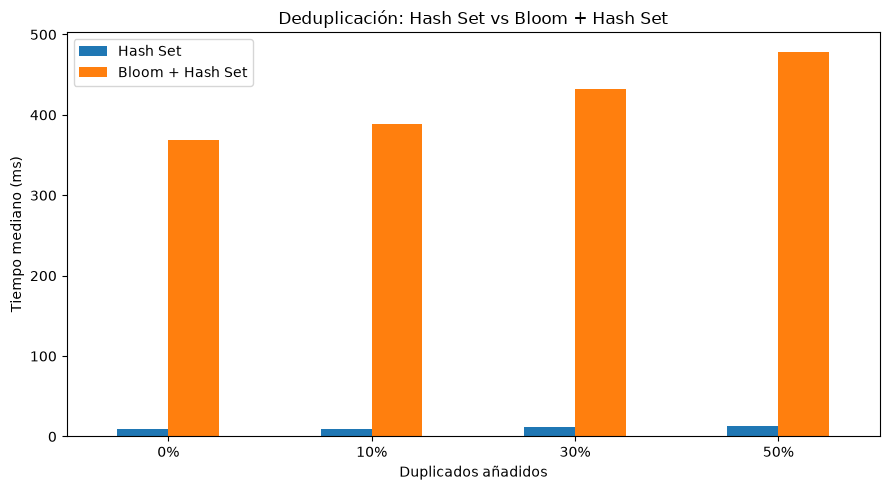

Benchmark Bloom Filter guardado correctamente.


In [9]:

import matplotlib.pyplot as plt

results_dir = PROJECT_DIR / "results"
figures_dir = PROJECT_DIR / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Exportar resultados
df_dedup_benchmark.to_csv(
    results_dir / "benchmark_bloom_dedup_raw.csv",
    index=False
)

summary_dedup.to_csv(
    results_dir / "benchmark_bloom_dedup_summary.csv",
    index=False
)

# Gráfico comparativo
ax = comparison_dedup[
    ["set", "hybrid"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Deduplicación: Hash Set vs Bloom + Hash Set"
)
ax.set_xlabel("Duplicados añadidos")
ax.set_ylabel("Tiempo mediano (ms)")
ax.legend(["Hash Set", "Bloom + Hash Set"])

plt.tight_layout()

plt.savefig(
    figures_dir / "benchmark_bloom_dedup.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Benchmark Bloom Filter guardado correctamente.")
